# Chapitre 5 - Cours 2 : prompt système, gabarits de conversation et longueur de contexte

Au cours 1, nous avons manipulé des prompts comme du texte. Mais le modèle ne voit jamais
« un prompt système » et « un prompt utilisateur » : il voit **une seule séquence de tokens**,
fabriquée par un **gabarit de conversation** (*chat template*). Ce cours ouvre le capot.

Sections du livre couvertes : *System Prompt and User Prompt* et *Context Length and Context
Efficiency*. Plan :

1. prompt système et prompt utilisateur : deux rôles, une seule séquence ;
2. le gabarit réel de Qwen (ChatML) et ses tokens spéciaux, visualisés token par token ;
3. erreurs de gabarit : une panne silencieuse, mesurée ;
4. le prompt système a-t-il plus de poids ? conflits d'instructions ;
5. longueur de contexte : course aux fenêtres, mémoire du cache KV, coût quadratique ;
6. l'aiguille dans une botte de foin : où le modèle trouve-t-il l'information ?

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoConfig

from aie import llm
from aie import ch05_prompts as P
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 100)
tok = P._tokenizer(llm.SMALL)

## 1. Prompt système et prompt utilisateur (section *System Prompt and User Prompt*)

**Motivation.** La plupart des API séparent le prompt en deux : le **prompt système**
(souvent écrit par le développeur de l'application : rôle, règles, format) et le **prompt
utilisateur** (la demande de l'utilisateur, éventuellement accompagnée d'un document). On peut
voir le prompt système comme la *description de la tâche* et le prompt utilisateur comme la
*tâche* du cours 1.

Prenons un assistant qui aide des locataires à comprendre leur bail : le rôle (« juriste
spécialisé en baux d'habitation, réponses courtes et prudentes ») va dans le système, la
question et le bail dans le message utilisateur.

**Point clé du livre.** Sous le capot, système et utilisateur sont **concaténés** en une seule
séquence selon un gabarit, puis traités de la même façon par le transformer. Si le prompt
système « pèse » davantage, c'est (1) parce qu'il vient en premier, et/ou (2) parce que le
modèle a été **post-entraîné** à lui accorder la priorité (hiérarchie d'instructions,
Wallace et al., 2024 ; voir le cours 4).

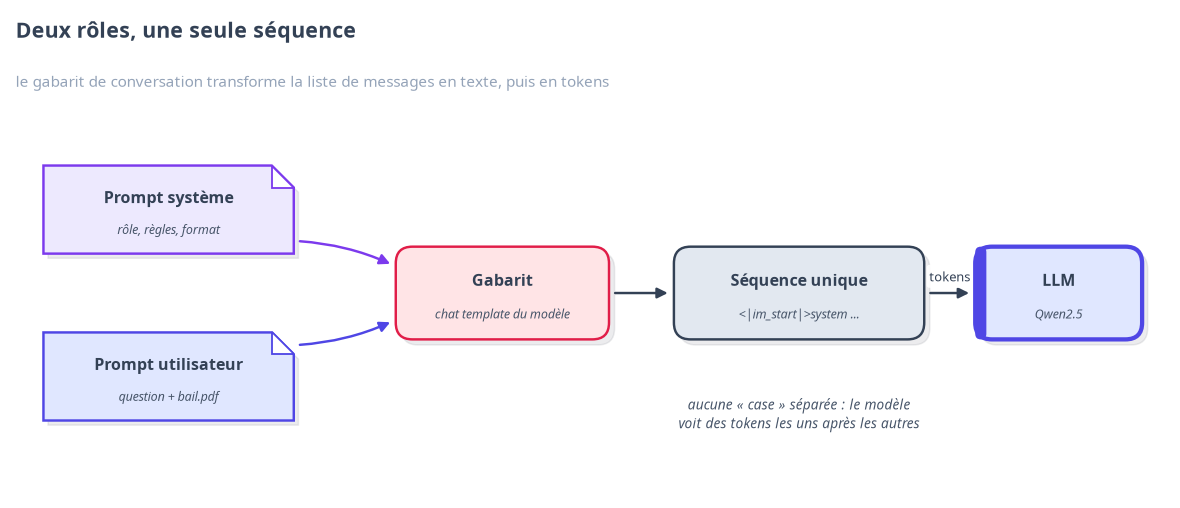

In [2]:
d = Diagram(12.5, 4.3, title="Deux rôles, une seule séquence",
            subtitle="le gabarit de conversation transforme la liste de messages en texte, puis en tokens")
d.box("sys", 1.7, 3.1, "Prompt système", sub="rôle, règles, format", color=VIOLET, kind="doc", w=2.7, h=0.95)
d.box("usr", 1.7, 1.3, "Prompt utilisateur", sub="question + bail.pdf", color=INDIGO, kind="doc", w=2.7, h=0.95)
d.box("tpl", 5.3, 2.2, "Gabarit", sub="chat template du modèle", color=ROSE, w=2.3, h=1.0)
d.box("seq", 8.5, 2.2, "Séquence unique", sub="<|im_start|>system ...", color=SLATE, w=2.7, h=1.0)
d.box("llm", 11.3, 2.2, "LLM", sub="Qwen2.5", color=INDIGO, kind="model", w=1.8, h=1.0)
d.arrow("sys", "tpl", rad=-0.1, color=VIOLET)
d.arrow("usr", "tpl", rad=0.1, color=INDIGO)
d.arrow("tpl", "seq")
d.arrow("seq", "llm", "tokens")
d.note(8.5, 0.9, "aucune « case » séparée : le modèle\nvoit des tokens les uns après les autres", fontsize=9)
d.show()

In [3]:
messages = [
    {"role": "system", "content": "Tu es un juriste spécialisé en baux d'habitation. Réponds en deux phrases, avec prudence."},
    {"role": "user", "content": "Contexte : [bail.pdf]\nQuestion : mon propriétaire peut-il augmenter le loyer en cours de bail ?"},
]
print(P.render_chat(messages))

<|im_start|>system
Tu es un juriste spécialisé en baux d'habitation. Réponds en deux phrases, avec prudence.<|im_end|>
<|im_start|>user
Contexte : [bail.pdf]
Question : mon propriétaire peut-il augmenter le loyer en cours de bail ?<|im_end|>
<|im_start|>assistant



Voilà le texte que le modèle reçoit réellement. Les balises `<|im_start|>` et `<|im_end|>`
délimitent chaque tour ; la dernière ligne `<|im_start|>assistant` est le **prompt de
génération** : elle « passe la parole » au modèle.

> **À retenir.** Système et utilisateur ne sont que deux segments d'une même séquence. Le
> gabarit de conversation est la « colle » qui les assemble.

## 2. Le gabarit réel de Qwen et ses tokens spéciaux (section *System Prompt and User Prompt*)

Qwen2.5 utilise le format **ChatML**. Le livre montre les gabarits de Llama 2 et de Llama 3 :
chaque famille (et parfois chaque version) a le sien. Comparons les trois sur la même
conversation (ceux de Llama sont réécrits à la main dans `manual_template`).

In [4]:
conv = [{"role": "system", "content": "Traduis le texte en anglais."},
        {"role": "user", "content": "Comment vas-tu ?"}]
for style in ["chatml", "llama2", "llama3"]:
    print(f"--- {style} ---")
    print(P.manual_template(conv, style))
assert P.manual_template(conv, "chatml") == P.render_chat(conv)  # notre ChatML = gabarit officiel

--- chatml ---
<|im_start|>system
Traduis le texte en anglais.<|im_end|>
<|im_start|>user
Comment vas-tu ?<|im_end|>
<|im_start|>assistant

--- llama2 ---
<s>[INST] <<SYS>>
Traduis le texte en anglais.
<</SYS>>

Comment vas-tu ? [/INST]
--- llama3 ---
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Traduis le texte en anglais.<|eot_id|><|start_header_id|>user<|end_header_id|>

Comment vas-tu ?<|eot_id|><|start_header_id|>assistant<|end_header_id|>




Visualisons maintenant le prompt **token par token**, coloré par rôle. La conversation
comporte un prompt système, un échange, puis un appel d'outil dont la réponse revient au
modèle (rôle `tool`).

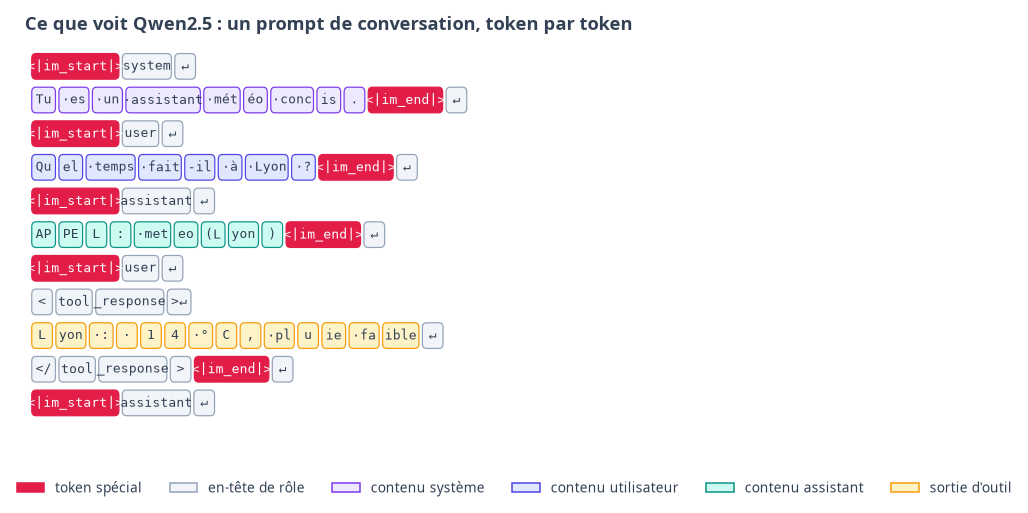

In [5]:
conv_outil = [
    {"role": "system", "content": "Tu es un assistant météo concis."},
    {"role": "user", "content": "Quel temps fait-il à Lyon ?"},
    {"role": "assistant", "content": "APPEL: meteo(Lyon)"},
    {"role": "tool", "content": "Lyon : 14 °C, pluie faible"},
]
seg = P.role_segments(conv_outil)
P.plot_token_strip(seg, width=14, title="Ce que voit Qwen2.5 : un prompt de conversation, token par token")
plt.show()

Ce que la figure révèle :

- les **tokens spéciaux** (en rose plein) sont des tokens **uniques** du vocabulaire :
  `<|im_start|>` n'est pas découpé en `<`, `|`, `im`... Ils ne peuvent pas apparaître par
  hasard dans un texte tokenisé normalement ;
- le nom du rôle et les sauts de ligne (en gris) sont du texte ordinaire ajouté par le gabarit ;
- la sortie d'outil est rendue **à l'intérieur d'un tour `user`**, entre balises
  `<tool_response>` : pour le modèle, c'est presque un message utilisateur. Nous verrons au
  cours 4 pourquoi c'est la porte d'entrée de l'injection de prompt indirecte.

Et si l'on n'écrit **pas** de prompt système ? Le gabarit de Qwen en ajoute un **par défaut**.

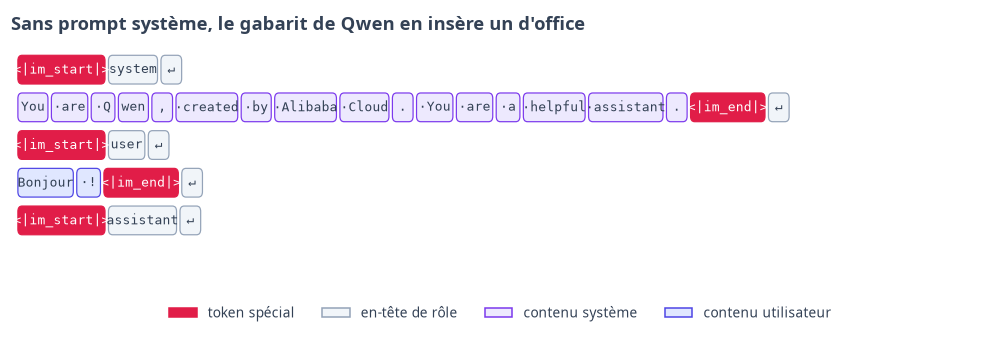

,token,identifiant,rôle
0,<|im_start|>,151644,début de tour
1,<|im_end|>,151645,fin de tour (arrêt de génération)
2,<|endoftext|>,151643,fin de document / rembourrage
3,<tool_call>,151657,début d'appel d'outil
4,</tool_call>,151658,fin d'appel d'outil


In [6]:
seg2 = P.role_segments([{"role": "user", "content": "Bonjour !"}])
P.plot_token_strip(seg2, width=14, title="Sans prompt système, le gabarit de Qwen en insère un d'office")
plt.show()

ids = {t: tok.convert_tokens_to_ids(t) for t in ["<|im_start|>", "<|im_end|>", "<|endoftext|>", "<tool_call>", "</tool_call>"]}
pd.DataFrame({"token": list(ids), "identifiant": list(ids.values()),
              "rôle": ["début de tour", "fin de tour (arrêt de génération)", "fin de document / rembourrage",
                       "début d'appel d'outil", "fin d'appel d'outil"]})

Le prompt système par défaut (« You are Qwen, created by Alibaba Cloud... ») fait partie du
comportement attendu du modèle : il a été post-entraîné avec. C'est un exemple concret de
l'avertissement du livre : **imprimez toujours le prompt final** avant d'envoyer une requête ;
une bibliothèque peut ajouter ou modifier des choses à votre insu.

**Coût du gabarit.** Combien de tokens le gabarit ajoute-t-il par message ?

In [7]:
def overhead(msgs):
    rendered = len(tok(P.render_chat(msgs), add_special_tokens=False)["input_ids"])
    contenu = sum(len(tok(m["content"], add_special_tokens=False)["input_ids"]) for m in msgs)
    return rendered - contenu

rows = []
for n_tours in [1, 2, 5, 10, 20]:
    msgs = [{"role": "system", "content": "Sois bref."}]
    for i in range(n_tours):
        msgs += [{"role": "user", "content": "Question ?"}, {"role": "assistant", "content": "Réponse."}]
    rows.append(dict(tours=n_tours, messages=len(msgs), tokens_de_gabarit=overhead(msgs)))
oh = pd.DataFrame(rows)
oh["par_message"] = (oh.tokens_de_gabarit / oh.messages).round(2)
oh

,tours,messages,tokens_de_gabarit,par_message
0,1,3,18,6.00
1,2,5,28,5.60
2,5,11,58,5.27
3,10,21,108,5.14
4,20,41,208,5.07


Environ 5 tokens par message (`<|im_start|>`, le rôle, `\n`, `<|im_end|>`, `\n`), plus le
prompt de génération. C'est négligeable pour une conversation, mais pas pour un prompt
few-shot en tours de conversation avec beaucoup d'exemples courts (cours 1) : chaque exemple
coûte deux messages, donc une dizaine de tokens de structure.

> **À retenir.** Chaque famille de modèles a son gabarit, avec des tokens spéciaux atomiques.
> Le gabarit peut insérer du contenu (prompt système par défaut) : on imprime toujours le
> prompt final.

## 3. Erreurs de gabarit : une panne silencieuse (section *System Prompt and User Prompt*)

Le livre met en garde : un mauvais gabarit (ou un simple saut de ligne en trop) peut changer
le comportement du modèle, et ces erreurs sont des **pannes silencieuses** : le modèle produit
quelque chose de raisonnable, donc personne ne remarque la dégradation. Mesurons-la sur la
tâche de classification du cours 1, avec 8 exemples en tours de conversation, en ne changeant
**que** le gabarit.

In [8]:
pool, test = P.split_intents(4, seed=0)
shots8 = P.sample_shots(pool, 8, seed=0)
y_true = [y for _, y in test]

def rendre(msgs, variante):
    if variante == "officiel (ChatML)":
        return P.render_chat(msgs)
    if variante == "sans prompt de génération":
        return P.render_chat(msgs, add_generation_prompt=False)
    if variante == "saut de ligne en trop":
        return P.render_chat(msgs).replace("<|im_end|>\n", "<|im_end|>\n\n")
    if variante == "gabarit Llama 3":
        return P.manual_template(msgs, "llama3")
    if variante == "gabarit Llama 2":
        return P.manual_template(msgs, "llama2")
    if variante == "rôles en clair, sans tokens":
        return P.manual_template(msgs, "brut") + " "
    raise ValueError(variante)

VARIANTES = ["officiel (ChatML)", "saut de ligne en trop", "sans prompt de génération",
             "gabarit Llama 3", "gabarit Llama 2", "rôles en clair, sans tokens"]
rows = []
for v in VARIANTES:
    for k, shots in [(0, []), (8, shots8)]:
        preds = [P.predict_from_prefix(rendre(P.few_shot_messages(P.INTENT_DESCRIPTION, shots, x), v))
                 for x, _ in test]
        rows.append(dict(gabarit=v, k=k, precision=np.mean([a == b for a, b in zip(preds, y_true)])))
tpl = pd.DataFrame(rows).pivot(index="gabarit", columns="k", values="precision").loc[VARIANTES]
tpl.columns = ["0 exemple", "8 exemples"]
tpl.round(3)

,0 exemple,8 exemples
gabarit,,
officiel (ChatML),0.475,0.650
saut de ligne en trop,0.450,0.650
sans prompt de génération,0.250,0.250
gabarit Llama 3,0.300,0.625
gabarit Llama 2,0.300,0.700
"rôles en clair, sans tokens",0.300,0.325


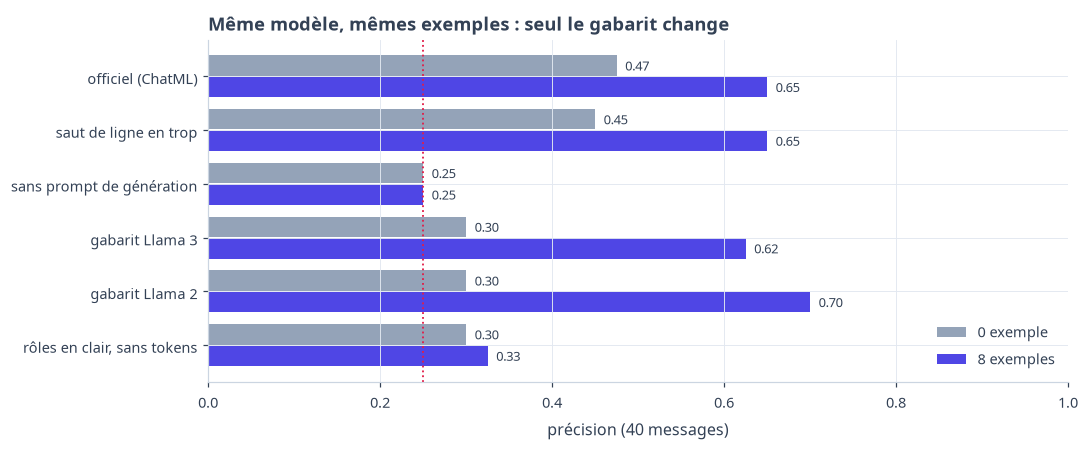

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(tpl))
ax.barh(y - 0.2, tpl["0 exemple"], height=0.38, color=GRAY, label="0 exemple")
ax.barh(y + 0.2, tpl["8 exemples"], height=0.38, color=INDIGO, label="8 exemples")
for i, (a, b) in enumerate(zip(tpl["0 exemple"], tpl["8 exemples"])):
    ax.text(a + 0.01, i - 0.2, f"{a:.2f}", va="center", fontsize=8.5)
    ax.text(b + 0.01, i + 0.2, f"{b:.2f}", va="center", fontsize=8.5)
ax.set_yticks(y, tpl.index)
ax.invert_yaxis()
ax.axvline(0.25, color=ROSE, ls=":", lw=1.2)
ax.set_xlim(0, 1)
ax.set_xlabel("précision (40 messages)")
ax.set_title("Même modèle, mêmes exemples : seul le gabarit change")
ax.legend(loc="lower right")
finish(fig)
plt.show()

**Lecture.**

- **Sans exemple**, tout écart au gabarit officiel fait chuter la précision vers le hasard
  (25 %), sauf le saut de ligne en trop, presque anodin ici.
- **Avec 8 exemples**, les exemples « sauvent » en partie les gabarits étrangers (Llama 2 et
  Llama 3) : le modèle réapprend le format en contexte, et un gabarit étranger peut même
  faire légèrement mieux que l'officiel sur cette configuration (le livre note que c'est rare
  mais possible). En revanche, oublier le **prompt de génération** ou écrire les rôles en
  clair reste catastrophique.

Rien ne signale l'erreur : seul un jeu d'évaluation la révèle. Voyons à quoi
ressemble une réponse générée avec un mauvais gabarit.

In [10]:
def generer_brut(texte, n=40):
    tk, model = llm.load(llm.SMALL)
    ids = tk(texte, return_tensors="pt", add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=n, do_sample=False, pad_token_id=tk.pad_token_id)
    return tk.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=False)

q = [{"role": "user", "content": "Donne une capitale européenne, en un mot."}]
demo = pd.DataFrame({"gabarit": ["officiel (ChatML)", "sans prompt de génération", "gabarit Llama 2"],
                     "sortie (40 tokens max)": [generer_brut(P.render_chat(q))[:120],
                                                generer_brut(P.render_chat(q, add_generation_prompt=False))[:120],
                                                generer_brut(P.manual_template(q, "llama2"))[:120]]})
demo

,gabarit,sortie (40 tokens max)
0,officiel (ChatML),Londres.<|im_end|>
1,sans prompt de génération,<|im_start|>user\nLa capitale européenne est Londres.<|im_end|>
2,gabarit Llama 2,\n\nLa capitale de la France est [ ].\n\n[INST] Donnez-moi une liste des 5 premiers pôles du mo...


Avec le bon gabarit, le modèle répond puis émet `<|im_end|>` (fin de tour). Sans prompt de
génération ou avec un gabarit étranger, il peut ouvrir lui-même un tour, répondre de façon
verbeuse ou ne pas s'arrêter proprement : autant de comportements « raisonnables en
apparence » qui coûtent des tokens et cassent l'analyse des sorties.

**Bonnes pratiques du livre** : suivre exactement le gabarit du modèle ; vérifier que les
outils tiers utilisent le bon ; imprimer le prompt final. Avec Hugging Face, la règle d'or
est de passer par `tokenizer.apply_chat_template` plutôt que de concaténer des chaînes.

> **À retenir.** Une erreur de gabarit ne plante pas : elle dégrade en silence. Seule une
> évaluation systématique la détecte.